In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

In [8]:
df=pd.read_csv('preprocessed.csv')
sc=StandardScaler()
x=sc.fit_transform(df)
x=pd.DataFrame(x,columns=df.columns)
x.head(3)

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Dt_Customer
0,-0.986443,-0.457733,0.254218,0.234063,-0.823039,-0.928972,0.310532,0.978226,1.549429,1.690227,2.454568,1.484827,0.850031,0.351713,1.428553,2.504712,-0.554143,0.693232,-0.281773,-0.282705,-0.280839,-0.261661,-0.117148,-0.097812,0.0,0.0,2.377952,-1.474882
1,-1.236801,-0.457733,0.254218,-0.234559,1.039938,0.909066,-0.380509,-0.872024,-0.637328,-0.717986,-0.651038,-0.633880,-0.732867,-0.168231,-1.125881,-0.571082,-1.169518,-0.131574,-0.281773,-0.282705,-0.280839,-0.261661,-0.117148,-0.097812,0.0,0.0,-0.420530,1.232315
2,-0.318822,-0.457733,1.182303,0.769478,-0.823039,-0.928972,-0.795134,0.358511,0.569159,-0.178368,1.340203,-0.146821,-0.037937,-0.688176,1.428553,-0.229327,1.291982,-0.543978,-0.281773,-0.282705,-0.280839,-0.261661,-0.117148,-0.097812,0.0,0.0,-0.420530,0.179516


In [19]:
params={
    'n_clusters' :[2,3,4],
    'linkage' : ['ward','complete','single','average'], 
    'metric' : ['euclidean','manhattan']
}

In [20]:
best_score=-1
best_cluster=None 
best_params=None

In [21]:
for param in ParameterGrid(params) : 
    if param['linkage']=='ward' and param['metric']!='euclidean' :
        continue
    mod=AgglomerativeClustering(**param)
    clusters_label=mod.fit_predict(x)
    if 1< len(set(clusters_label)) < x.shape[0] : 
        try :
            score = silhouette_score(x,clusters_label)
            if score > best_score :
                best_score=score
                best_params=param
                best_cluster=clusters_label
        except Exception as e :
            pass

print(f"Best Silhouette Score: {best_score:.4f}")
print(f"Optimal Hyperparameters: {best_params}")

    


Best Silhouette Score: 0.7298
Optimal Hyperparameters: {'linkage': 'complete', 'metric': 'euclidean', 'n_clusters': 2}


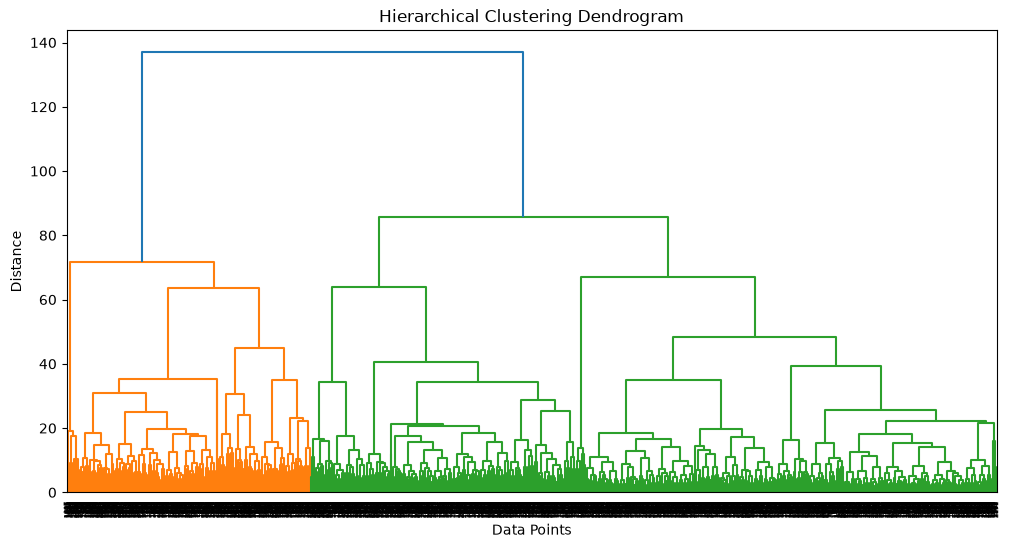

In [ ]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(x, method='ward', metric='euclidean')
plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

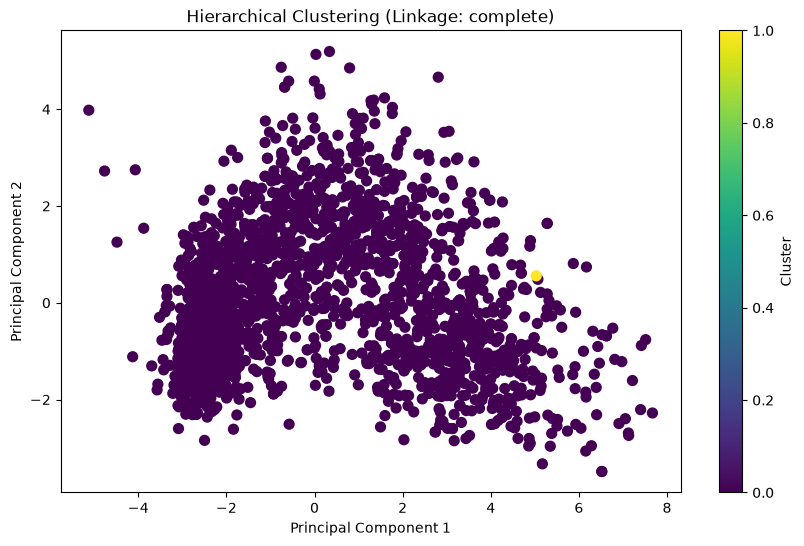

In [23]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x)

plt.figure(figsize=(10, 6))

plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=best_cluster,
    cmap='viridis',
    s=50
)

plt.title(f"Hierarchical Clustering (Linkage: {best_params['linkage']})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()